<a href="https://colab.research.google.com/github/Hazem-Barkallah/DS-ML-Projects/blob/main/Agri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Data

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p /content/plantvillage --unzip

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:19<00:00, 113MB/s] 



In [ ]:
for root, dirs, files in os.walk("/content/plantvillage"):
    print(root,dirs,files)
    break

/content/plantvillage ['plantvillage dataset'] []


Le dossier `color`.

In [ ]:
DATA_DIR = glob.glob("/content/**/color",recursive=True)[0]
print("Dossier:", DATA_DIR)
print(len(os.listdir(DATA_DIR))) #nbr de classes

Dossier: /content/plantvillage/plantvillage dataset/color
38


# Params

In [ ]:
IMG_SIZE = (224, 224)       # taille des images
BATCH_SIZE = 32
MAX_PAR_CLASSE = 100        # None = toutes les images
EPOCHS_TETE = 3             # entraînement de la dernière couche
EPOCHS_FINETUNING = 3       # fine-tuning
POIDS = "imagenet"          # poids pré-entraînés
SEED = 42

keras.utils.set_random_seed(SEED)



## Exploration

In [ ]:
lignes = []
for classe in sorted(os.listdir(DATA_DIR)):
    classe_dossier = os.path.join(DATA_DIR, classe)
    if not os.path.isdir(classe_dossier):
        continue
    for fichier in os.listdir(classe_dossier):
        if fichier.lower().endswith((".jpg", ".jpeg", ".png")):
            lignes.append((os.path.join(classe_dossier, fichier), classe)) #append des tuples (path de classe, nom de la classe)

df = pd.DataFrame(lignes, columns=["chemin", "classe"])

# # On garde au maximum MAX_PAR_CLASSE images par classe (choisies au hasard)
# if MAX_PAR_CLASSE:
#     df = df.sample(frac=1, random_state=SEED).groupby("classe").head(MAX_PAR_CLASSE)
# df = df.reset_index(drop=True)

# # Chaque classe reçoit un numéro (c'est ce que le modèle apprend à prédire)
# classes = sorted(df["classe"].unique())
# df["label"] = df["classe"].map({c: i for i, c in enumerate(classes)})
# NUM_CLASSES = len(classes)

# print(len(df), "images,", NUM_CLASSES, "classes")
# df.head()

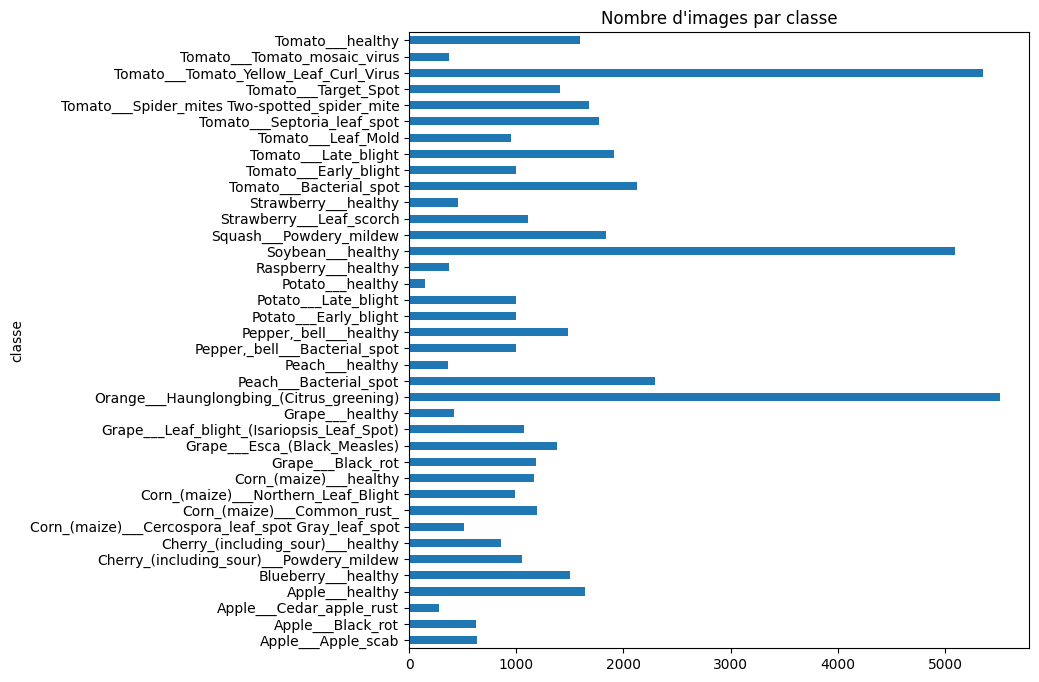

In [ ]:
# Nombre d'images par classe
df["classe"].value_counts().sort_index().plot.barh(figsize=(8, 8))
plt.title("Nombre d'images par classe")
plt.show()

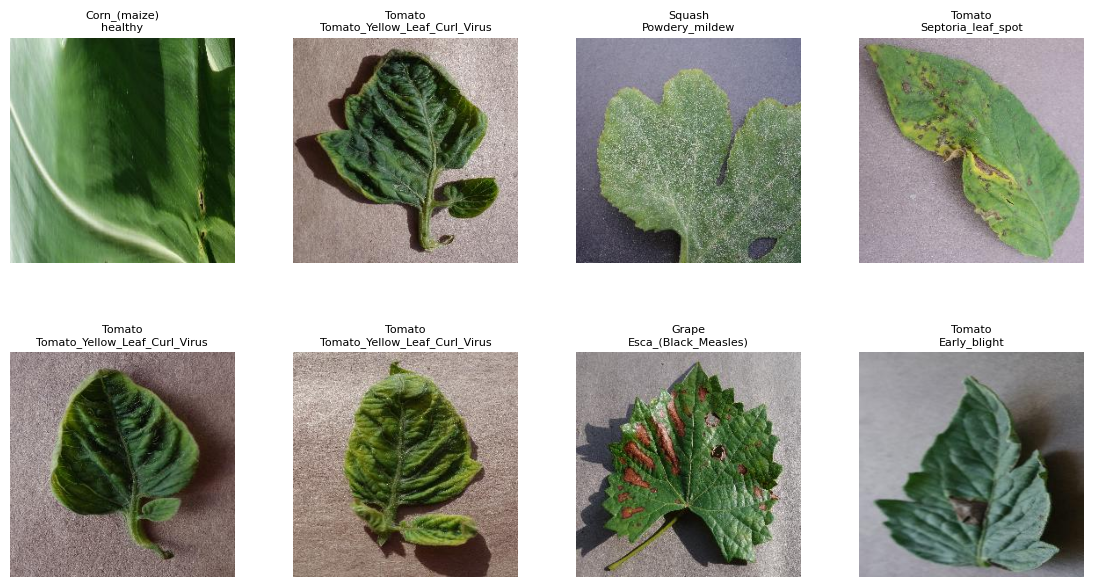

In [ ]:
# Quelques images au hasard
exemples = df.sample(8, random_state=SEED)
plt.figure(figsize=(14, 7))
for k, (_, ligne) in enumerate(exemples.iterrows()):
    plt.subplot(2, 4, k + 1)
    plt.imshow(Image.open(ligne["chemin"]).convert("RGB"))
    plt.title(ligne["classe"].replace("___", "\n"), fontsize=8)
    plt.axis("off")
plt.subplots_adjust(top=0.88, hspace=0.4)
plt.show()

## 5. Découpage train / validation / test

- **train (70 %)** : le modèle apprend dessus.
- **validation (15 %)** : on suit les progrès pendant l'entraînement.
- **test (15 %)** : on ne l'utilise qu'à la fin, pour juger le modèle honnêtement.

`stratify` garde les mêmes proportions de chaque classe dans les trois ensembles.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

print("train :", len(train_df))
print("validation :", len(val_df))
print("test :", len(test_df))

# Vérification : aucune image ne doit être dans deux ensembles
assert not set(train_df["chemin"]) & set(test_df["chemin"])
assert not set(train_df["chemin"]) & set(val_df["chemin"])
assert not set(val_df["chemin"]) & set(test_df["chemin"])

## 6. Prétraitement

Pour chaque image :
1. on la **lit** ;
2. on la **redimensionne** à la même taille (224 x 224) ;
3. on regroupe les images par **lots** (batch).

La **normalisation** des pixels (mise à l'échelle) est faite dans le modèle, à l'étape suivante.

In [ ]:
def charger(chemin, label):
    img = tf.io.read_file(chemin)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label


def creer_dataset(donnees, melanger=False):
    ds = tf.data.Dataset.from_tensor_slices((donnees["chemin"].values, donnees["label"].values))
    if melanger:
        ds = ds.shuffle(len(donnees), seed=SEED)
    return ds.map(charger).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = creer_dataset(train_df, melanger=True)
val_ds = creer_dataset(val_df)
test_ds = creer_dataset(test_df)
print("Datasets prêts")

### Augmentation de données

Pour éviter que le modèle apprenne les images par cœur, on les modifie un peu au hasard
(retournement, rotation, zoom). Elle n'est active que pendant l'entraînement.

In [ ]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
])

# Aperçu : la même image, transformée 4 fois
image, _ = charger(train_df["chemin"].iloc[0], 0)
plt.figure(figsize=(12, 3.5))
for k in range(4):
    plt.subplot(1, 4, k + 1)
    plt.imshow(augmentation(image[None, ...], training=True)[0].numpy().astype("uint8"))
    plt.axis("off")
plt.show()

## 7. Modèle : transfer learning avec MobileNetV2

MobileNetV2 a déjà appris à reconnaître plein de formes sur des millions d'images (ImageNet).
On le réutilise et on ajoute seulement une petite couche finale pour nos 38 classes.

- `base` : MobileNetV2 (gelé : ses poids ne changent pas au début).
- `Rescaling` : met les pixels à l'échelle attendue par MobileNetV2.
- `Dense` : la couche finale qui donne une probabilité par classe.

In [ ]:
base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), include_top=False, weights=POIDS)
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    augmentation,
    layers.Rescaling(1 / 127.5, offset=-1),       # pixels de [0, 255] vers [-1, 1]
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
print("Paramètres :", f"{model.count_params():,}")

## 8. Entraînement

**Étape 1 :** on entraîne seulement la couche finale (le reste de MobileNetV2 est gelé).

In [ ]:
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TETE, verbose=2)

plt.plot(hist1.history["accuracy"], label="train")
plt.plot(hist1.history["val_accuracy"], label="validation")
plt.title("Accuracy - étape 1")
plt.xlabel("Époque")
plt.legend()
plt.show()

**Étape 2 : fine-tuning.** On dégèle les 30 dernières couches de MobileNetV2 et on continue
avec un learning rate très petit, pour ajuster finement le modèle à nos feuilles.

In [ ]:
base.trainable = True
for couche in base.layers[:-30]:
    couche.trainable = False
for couche in base.layers[-30:]:
    if isinstance(couche, layers.BatchNormalization):
        couche.trainable = False          # on garde les BatchNorm gelées (plus stable)

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNING, verbose=2)

plt.plot(hist2.history["accuracy"], label="train")
plt.plot(hist2.history["val_accuracy"], label="validation")
plt.title("Accuracy - fine-tuning")
plt.xlabel("Époque")
plt.legend()
plt.show()

## 9. Évaluation sur le jeu de test

On prédit la classe de chaque image de test, puis on compare avec la vraie classe.

- **Accuracy** : part des images bien classées.
- **F1 macro** : moyenne du F1 de chaque classe (donne le même poids à toutes les classes).

In [ ]:
probas = model.predict(test_ds, verbose=0)
y_pred = probas.argmax(axis=1)                 # classe prédite = la plus probable
y_true = test_df["label"].values               # vraie classe

acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average="macro")
print(f"Accuracy : {acc:.4f}")
print(f"F1 macro : {f1:.4f}")

### Résultats par classe

In [ ]:
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES),
                            target_names=classes, zero_division=0))

### Matrice de confusion

Chaque ligne = vraie classe, chaque colonne = classe prédite. Une bonne matrice a une diagonale
bien foncée.

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))

plt.figure(figsize=(12, 12))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(NUM_CLASSES), classes, rotation=90, fontsize=7)
plt.yticks(range(NUM_CLASSES), classes, fontsize=7)
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion")
plt.colorbar()
plt.tight_layout()
plt.show()

### Les erreurs les plus fréquentes

In [ ]:
resultats = pd.DataFrame({
    "vraie classe": [classes[i] for i in y_true],
    "classe prédite": [classes[i] for i in y_pred],
})
erreurs = resultats[resultats["vraie classe"] != resultats["classe prédite"]]
print(len(erreurs), "erreurs sur", len(resultats), "images de test\n")
erreurs.value_counts().head(10)

### Quelques images mal classées

In [ ]:
idx_erreurs = np.where(y_pred != y_true)[0]

if len(idx_erreurs) == 0:
    print("Aucune erreur sur le jeu de test.")
else:
    plt.figure(figsize=(14, 7))
    for k, i in enumerate(idx_erreurs[:8]):
        plt.subplot(2, 4, k + 1)
        plt.imshow(Image.open(test_df["chemin"].iloc[i]).convert("RGB"))
        plt.title(f"vrai : {classes[y_true[i]]}\nprédit : {classes[y_pred[i]]}",
                  fontsize=8, color="red")
        plt.axis("off")
    plt.subplots_adjust(top=0.85, hspace=0.5)
    plt.show()

## 10. Prédire une image

Téléverse une photo de feuille et regarde ce que le modèle prédit.

In [ ]:
from google.colab import files
up = files.upload()
nom = list(up.keys())[0]

In [ ]:
img = tf.keras.utils.load_img(nom, target_size=IMG_SIZE)
x = np.expand_dims(tf.keras.utils.img_to_array(img), axis=0)
proba = model.predict(x, verbose=0)[0]

plt.imshow(img)
plt.axis("off")
plt.show()

print("Les 3 prédictions les plus probables :")
for i in proba.argsort()[::-1][:3]:
    print(f"  {classes[i]} : {proba[i]:.1%}")

### Sauvegarder le modèle

In [ ]:
model.save("modele_plantes.keras")

from google.colab import files
files.download("modele_plantes.keras")

## 11. Bonus : comparer avec un CNN simple (from scratch)

Pour savoir si le transfer learning aide vraiment, on entraîne un petit CNN **sans** poids
pré-entraînés, sur les mêmes données, et on compare.

In [ ]:
cnn = keras.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    augmentation,
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])

cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

cnn.fit(train_ds, validation_data=val_ds,
        epochs=EPOCHS_TETE + EPOCHS_FINETUNING, verbose=2)

In [ ]:
y_pred_cnn = cnn.predict(test_ds, verbose=0).argmax(axis=1)

comparaison = pd.DataFrame({
    "Modèle": ["CNN simple (from scratch)", "MobileNetV2 (transfer learning)"],
    "Accuracy": [accuracy_score(y_true, y_pred_cnn), acc],
    "F1 macro": [f1_score(y_true, y_pred_cnn, average="macro"), f1],
}).round(4)
comparaison